# 01. Data Cleaning and EDA: Coffee Sales

**Goal:** understand the coffee-shop sales data before forecasting it.

**Data:** `data/raw/Coffe_sales.csv`, one row per card transaction, 1 Mar 2024 to 23 Mar 2025. The file does not state a currency, so money is shown as plain numbers.

**Note:** this is a historical dataset, so everything here is a portfolio analysis, not a live business forecast.

**Questions**
1. Is the data clean and complete?
2. How do sales change by day, weekday, hour and product?
3. Why did daily revenue jump in early 2025?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
BROWN, RED, GREY = "#6F4E37", "#C1272D", "#9AA0A6"

# Works whether the notebook is run from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "Coffe_sales.csv"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
for p in (PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

## 1. Load and inspect

In [2]:
df = pd.read_csv(RAW)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (3547, 11)


,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000


In [3]:
display(df.dtypes.to_frame("dtype").join(df.isna().sum().to_frame("missing")).join(df.nunique().to_frame("unique")))
df.describe(include="all").T

,dtype,missing,unique
hour_of_day,int64,0,17
cash_type,str,0,1
money,float64,0,13
coffee_name,str,0,8
Time_of_Day,str,0,3
Weekday,str,0,7
Month_name,str,0,12
Weekdaysort,int64,0,7
Monthsort,int64,0,12
Date,str,0,381


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hour_of_day,3547.0,NaN,NaN,NaN,14.185791,4.23401,6.0,10.0,14.0,18.0,22.0
cash_type,3547,1,card,3547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
money,3547.0,NaN,NaN,NaN,31.645216,4.877754,18.12,27.92,32.82,35.76,38.7
coffee_name,3547,8,Americano with Milk,809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_of_Day,3547,3,Afternoon,1205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekday,3547,7,Tue,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month_name,3547,12,Mar,494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekdaysort,3547.0,NaN,NaN,NaN,3.845785,1.971501,1.0,2.0,4.0,6.0,7.0
Monthsort,3547.0,NaN,NaN,NaN,6.453905,3.500754,1.0,3.0,7.0,10.0,12.0
Date,3547,381,2024-10-11,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality checks

Each check below should return 0. If one does not, the column cannot be trusted.

In [4]:
df["Date"] = pd.to_datetime(df["Date"])
# Time is text; some rows have fractional seconds and some do not, so convert it with to_timedelta
df["timestamp"] = df["Date"] + pd.to_timedelta(df["Time"])

checks = {
    "duplicate rows": int(df.duplicated().sum()),
    "missing values": int(df.isna().sum().sum()),
    "hour_of_day differs from Time": int((df["timestamp"].dt.hour != df["hour_of_day"]).sum()),
    "Weekday differs from Date": int((df["Date"].dt.strftime("%a") != df["Weekday"]).sum()),
    "Month_name differs from Date": int((df["Date"].dt.strftime("%b") != df["Month_name"]).sum()),
    "money <= 0": int((df["money"] <= 0).sum()),
}
display(pd.Series(checks, name="rows failing").to_frame())
display(df.loc[df["timestamp"].dt.hour != df["hour_of_day"], ["Date", "Time", "hour_of_day"]])
print("The one hour mismatch is a sale at 16:59:59.993 stored as hour 17 (rounding): harmless.")
print("cash_type values:", df["cash_type"].unique(), "-> one value only, so it carries no information")
print("Time_of_Day hour ranges:")
display(df.groupby("Time_of_Day")["hour_of_day"].agg(["min", "max"]))

,rows failing
duplicate rows,0
missing values,0
hour_of_day differs from Time,1
Weekday differs from Date,0
Month_name differs from Date,0
money <= 0,0


,Date,Time,hour_of_day
3483,2025-03-19,16:59:59.993000,17


The one hour mismatch is a sale at 16:59:59.993 stored as hour 17 (rounding): harmless.
cash_type values: <ArrowStringArray>
['card']
Length: 1, dtype: str -> one value only, so it carries no information
Time_of_Day hour ranges:


,min,max
Time_of_Day,,
Afternoon,12,16
Morning,6,11
Night,17,22


### Prices

Each product has a small number of price points. If prices changed over time, revenue can move even when the number of sales does not.

In [5]:
price_tbl = df.groupby("coffee_name")["money"].agg(["min", "max", "nunique"]).round(2)
price_tbl.columns = ["lowest price", "highest price", "distinct prices"]
display(price_tbl)

df["month"] = df["Date"].dt.to_period("M")
price_by_month = df.pivot_table(index="month", columns="coffee_name", values="money", aggfunc="median").round(2)
price_by_month

,lowest price,highest price,distinct prices
coffee_name,,,
Americano,23.02,28.9,4
Americano with Milk,27.92,33.8,4
Cappuccino,32.82,38.7,4
Cocoa,32.82,38.7,4
Cortado,23.02,28.9,4
Espresso,18.12,24.0,4
Hot Chocolate,32.82,38.7,4
Latte,32.82,38.7,4


coffee_name,Americano,Americano with Milk,Cappuccino,Cocoa,Cortado,Espresso,Hot Chocolate,Latte
month,,,,,,,,
2024-03,28.90,33.80,38.70,38.70,28.90,24.00,38.70,38.70
2024-04,28.90,33.80,38.70,38.70,28.90,24.00,38.70,38.70
2024-05,27.92,32.82,37.72,37.72,27.92,23.02,37.72,37.72
2024-06,27.92,32.82,37.72,37.72,27.92,23.02,37.72,37.72
2024-07,23.02,27.92,32.82,32.82,23.02,18.12,32.82,32.82
2024-08,23.02,27.92,32.82,32.82,23.02,18.12,32.82,32.82
2024-09,23.02,27.92,32.82,32.82,23.02,18.12,32.82,32.82
2024-10,25.96,30.86,35.76,35.76,25.96,21.06,35.76,35.76
2024-11,25.96,30.86,35.76,35.76,25.96,21.06,35.76,35.76


## 3. Build the daily table

In [6]:
cal = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
daily = (df.groupby("Date")
           .agg(revenue=("money", "sum"), transactions=("money", "size"))
           .reindex(cal)
           .rename_axis("date"))
daily["reported"] = daily["transactions"].notna()
daily[["revenue", "transactions"]] = daily[["revenue", "transactions"]].fillna(0)
daily["transactions"] = daily["transactions"].astype(int)
daily["avg_price"] = (daily["revenue"] / daily["transactions"]).where(daily["reported"])
daily["weekday"] = daily.index.strftime("%a")
daily["revenue_ma7"] = daily["revenue"].where(daily["reported"]).rolling(7, min_periods=4).mean()

missing_days = daily.index[~daily["reported"]]
print(f"Calendar days: {len(daily)} | days with sales: {daily['reported'].sum()} | days with no data: {len(missing_days)}")
print("Days with no data:", [d.strftime("%Y-%m-%d") for d in missing_days])
daily.to_csv(PROC / "daily_sales.csv")
daily.head()

Calendar days: 388 | days with sales: 381 | days with no data: 7
Days with no data: ['2024-05-01', '2024-05-04', '2024-05-05', '2024-11-27', '2025-01-01', '2025-01-19', '2025-01-23']


,revenue,transactions,reported,avg_price,weekday,revenue_ma7
date,,,,,,
2024-03-01,396.3,11,True,36.027273,Fri,NaN
2024-03-02,188.1,6,True,31.350000,Sat,NaN
2024-03-03,309.1,9,True,34.344444,Sun,NaN
2024-03-04,135.2,4,True,33.800000,Mon,257.175
2024-03-05,338.5,9,True,37.611111,Tue,273.440


Seven calendar days have no transactions at all (the shop was probably closed, or the data was not recorded). They are **kept in the calendar and flagged**, not filled with zero revenue, because a zero would look like a real very bad day and distort the models later.

## 4. Daily revenue over time

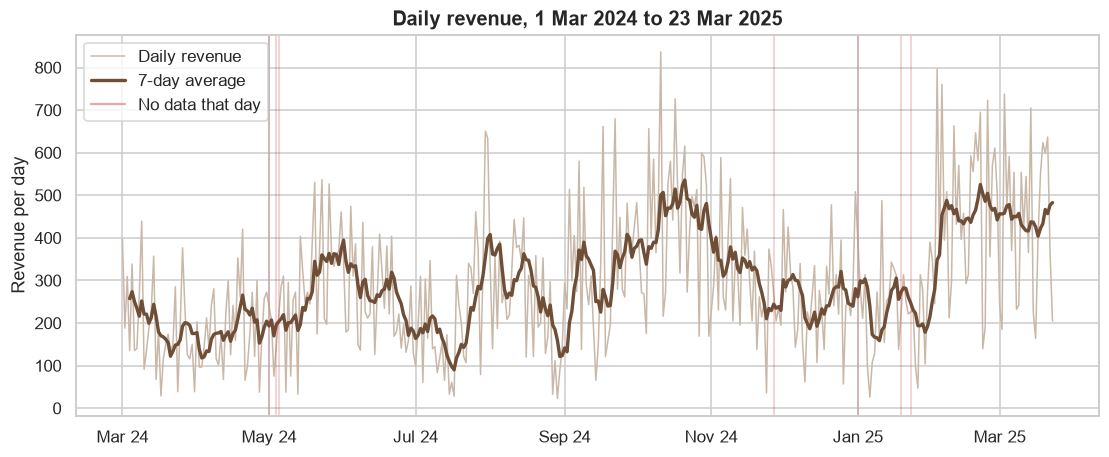

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
rep = daily[daily["reported"]]
ax.plot(rep.index, rep["revenue"], color="#C9B8A8", lw=1, label="Daily revenue")
ax.plot(daily.index, daily["revenue_ma7"], color=BROWN, lw=2.2, label="7-day average")
for d in missing_days:
    ax.axvline(d, color=RED, alpha=.25, lw=1)
ax.plot([], [], color=RED, alpha=.4, label="No data that day")
ax.set(title="Daily revenue, 1 Mar 2024 to 23 Mar 2025", ylabel="Revenue per day", xlabel="")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.legend(loc="upper left")
save_fig("01_daily_revenue.png")

## 5. The level shift in early 2025: volume or price?

Biggest jump starts in the week ending 2025-02-09 (next 4 weeks are 1.9x the previous 8)


,8 weeks before,from the jump on,change
revenue per day,240.45,461.37,+92%
transactions per day,7.55,14.78,+96%
average price per sale,31.69,31.15,-2%


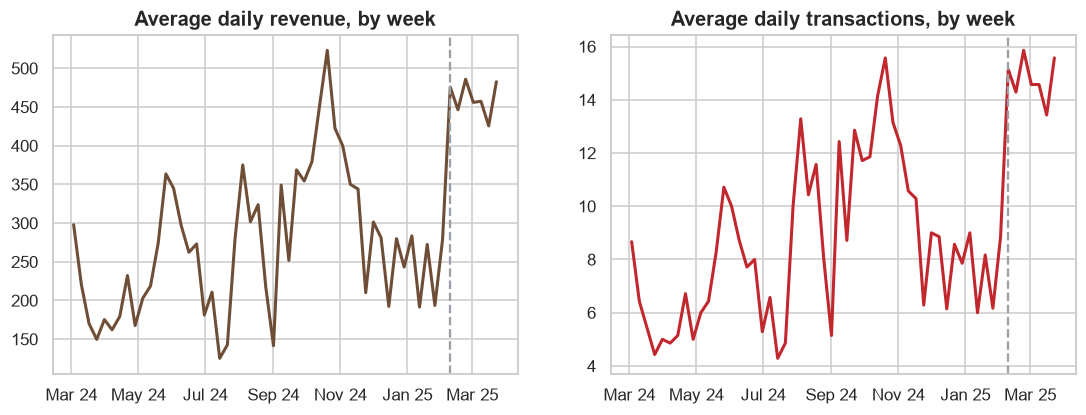

In [8]:
weekly = (daily[daily["reported"]]
          .resample("W-SUN")
          .agg(avg_daily_revenue=("revenue", "mean"), avg_daily_transactions=("transactions", "mean")))

# biggest jump: next 4 weeks' average divided by the previous 8 weeks' average, largest ratio over all weeks
w = weekly["avg_daily_revenue"]
ratio = pd.Series({w.index[i]: w.iloc[i:i + 4].mean() / w.iloc[i - 8:i].mean() for i in range(8, len(w) - 3)})
jump_week = ratio.idxmax()
before = daily.loc[:jump_week - pd.Timedelta(days=7)]
before = before[before["reported"]].tail(56)
after = daily.loc[jump_week - pd.Timedelta(days=6):]
after = after[after["reported"]]

summary = pd.DataFrame({
    "8 weeks before": [before["revenue"].mean(), before["transactions"].mean(), before["avg_price"].mean()],
    "from the jump on": [after["revenue"].mean(), after["transactions"].mean(), after["avg_price"].mean()],
}, index=["revenue per day", "transactions per day", "average price per sale"]).round(2)
summary["change"] = (summary["from the jump on"] / summary["8 weeks before"] - 1).map("{:+.0%}".format)
print("Biggest jump starts in the week ending", jump_week.date(), f"(next 4 weeks are {ratio.max():.1f}x the previous 8)")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(weekly.index, weekly["avg_daily_revenue"], color=BROWN, lw=2)
axes[0].set(title="Average daily revenue, by week")
axes[1].plot(weekly.index, weekly["avg_daily_transactions"], color=RED, lw=2)
axes[1].set(title="Average daily transactions, by week")
for a in axes:
    a.axvline(jump_week, color=GREY, ls="--"); a.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
save_fig("02_level_shift.png")

**Reading this:** the biggest jump comes from the **number of sales per day**, not from higher prices (average price per sale barely moves). The data cannot tell us why more customers came (new location, promotion, opening hours?).

Revenue also moves a lot at other times (a peak around Oct 2024, a low in Jan 2025), so this is a series whose level keeps changing. Any forecast has to be tested on recent days, not only on the whole history.

## 6. Weekday and hour patterns

,all history,since the jump
weekday,,
Mon,315.7,638.2
Tue,330.3,449.7
Wed,302.9,615.2
Thu,298.0,473.8
Fri,300.0,580.3
Sat,267.9,244.3
Sun,247.0,228.1


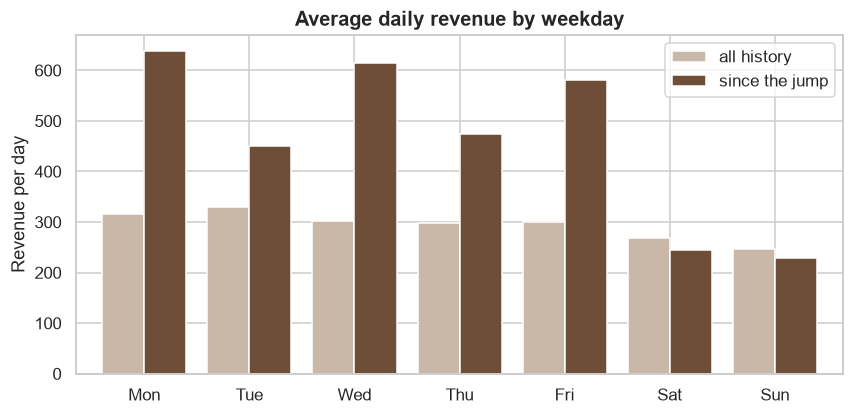

In [9]:
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
recent = daily[daily["reported"] & (daily.index >= after.index.min())]
wk = pd.DataFrame({
    "all history": daily[daily["reported"]].groupby("weekday")["revenue"].mean(),
    "since the jump": recent.groupby("weekday")["revenue"].mean(),
}).loc[order].round(1)
display(wk)

fig, ax = plt.subplots(figsize=(9, 4))
wk.plot.bar(ax=ax, color=["#C9B8A8", BROWN], width=.8)
ax.set(title="Average daily revenue by weekday", xlabel="", ylabel="Revenue per day"); ax.tick_params(axis="x", rotation=0)
save_fig("03_weekday.png")

Top 5 hours by share of revenue:
 hour_of_day
10    9.1%
16    8.0%
11    7.5%
19    6.9%
17    6.8%


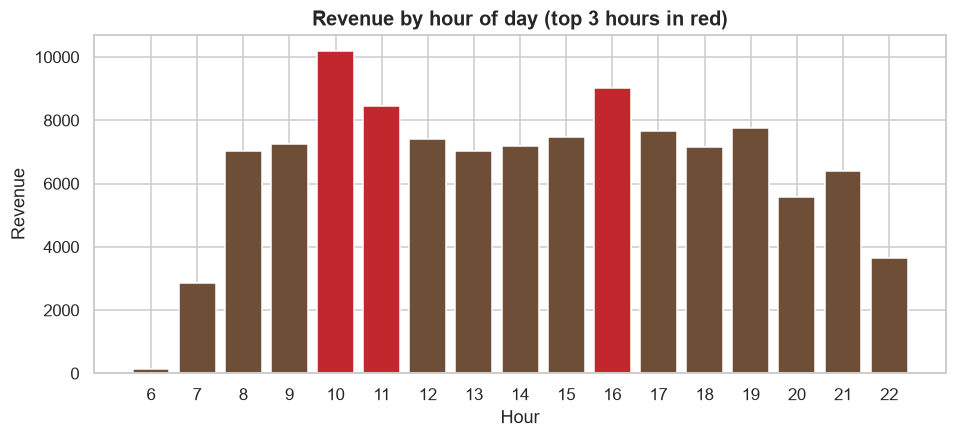

In [10]:
hourly = df.groupby("hour_of_day")["money"].agg(revenue="sum", transactions="size")
hourly["share"] = hourly["revenue"] / hourly["revenue"].sum()
top_hours = hourly["share"].nlargest(5).round(3)
print("Top 5 hours by share of revenue:\n", top_hours.map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
colors = [RED if h in top_hours.index[:3] else BROWN for h in hourly.index]
ax.bar(hourly.index, hourly["revenue"], color=colors)
ax.set(title="Revenue by hour of day (top 3 hours in red)", xlabel="Hour", ylabel="Revenue"); ax.set_xticks(hourly.index)
save_fig("04_hourly.png")

## 7. Products

,revenue,transactions,avg_price,revenue_share
coffee_name,,,,
Latte,26875.30,757,35.502,23.9%
Americano with Milk,24751.12,809,30.595,22.1%
Cappuccino,17439.14,486,35.883,15.5%
Americano,14650.26,564,25.976,13.1%
Hot Chocolate,9933.46,276,35.991,8.8%
Cocoa,8521.16,239,35.653,7.6%
Cortado,7384.86,287,25.731,6.6%
Espresso,2690.28,129,20.855,2.4%


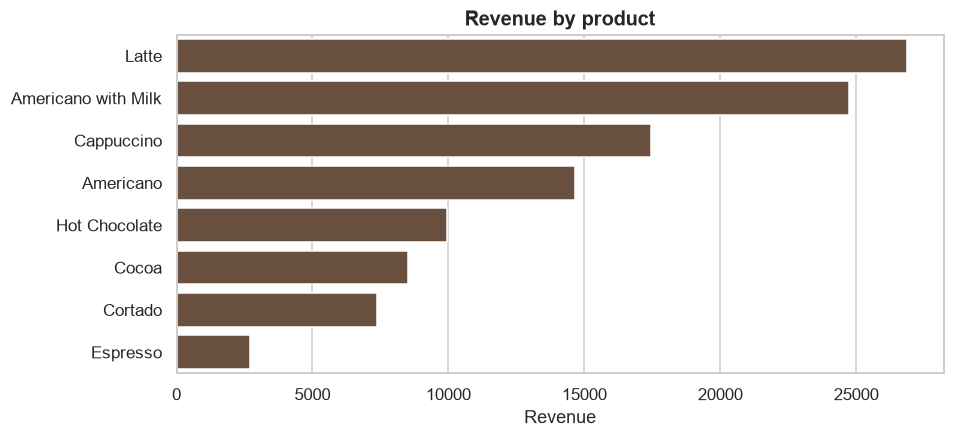

In [11]:
prod = (df.groupby("coffee_name")["money"].agg(revenue="sum", transactions="size", avg_price="mean")
          .sort_values("revenue", ascending=False))
prod["revenue_share"] = prod["revenue"] / prod["revenue"].sum()
display(prod.round(3).assign(revenue_share=lambda t: t["revenue_share"].map("{:.1%}".format)))
prod.to_csv(TAB / "product_mix.csv")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=prod["revenue"], y=prod.index, color=BROWN, ax=ax)
ax.set(title="Revenue by product", xlabel="Revenue", ylabel="")
save_fig("05_products.png")

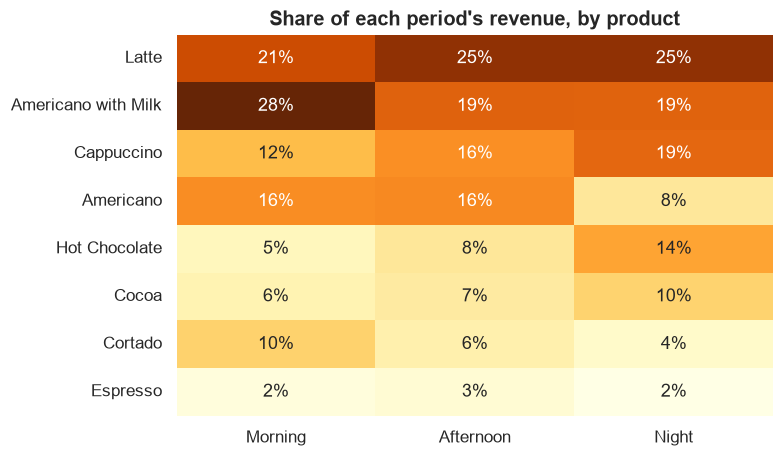

In [12]:
tod = df.pivot_table(index="coffee_name", columns="Time_of_Day", values="money", aggfunc="sum")[["Morning", "Afternoon", "Night"]]
tod_share = tod / tod.sum()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(tod_share.loc[prod.index], annot=True, fmt=".0%", cmap="YlOrBr", cbar=False, ax=ax)
ax.set(title="Share of each period's revenue, by product", xlabel="", ylabel="")
save_fig("06_product_by_time_of_day.png")
tod_share.round(3).to_csv(TAB / "product_share_by_time_of_day.csv")

## 8. How noisy is a single day?

count    381.0
mean     294.6
std      163.2
min       23.0
25%      172.4
50%      272.4
75%      380.6
max      836.7

Days under 50 in revenue: 13 (3.4% of days)


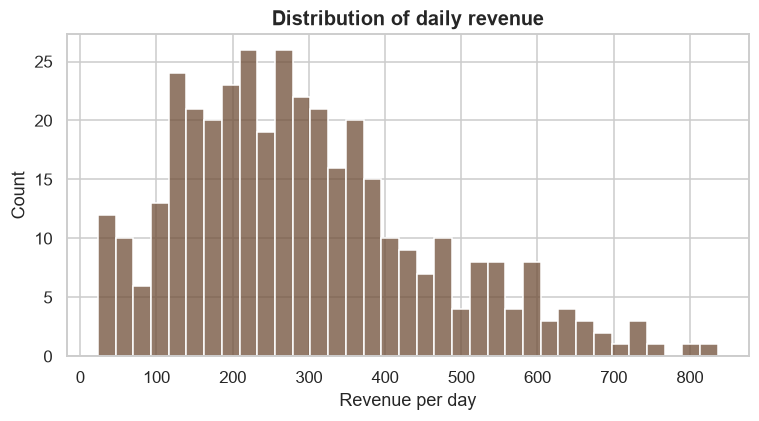

In [13]:
r = daily.loc[daily["reported"], "revenue"]
print(r.describe().round(1).to_string())
low = r[r < 50]
print(f"\nDays under 50 in revenue: {len(low)} ({len(low)/len(r):.1%} of days)")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(r, bins=35, color=BROWN, ax=ax)
ax.set(title="Distribution of daily revenue", xlabel="Revenue per day")
save_fig("07_daily_distribution.png")

Daily revenue is very spread out, and a few days are close to zero. Percentage errors such as **SMAPE blow up on those days**, so later notebooks also use **WAPE** (total absolute error divided by total revenue), which is steadier.

## 9. Findings

In [14]:
share = prod["revenue_share"]
peak = hourly["share"].idxmax()
print("1. Data quality: no duplicates, no missing values; derived columns agree with Date/Time (one harmless rounding case).")
print(f"2. {len(missing_days)} calendar days have no transactions; they are flagged, not filled with zero.")
print(f"3. Revenue per day rose from {summary.loc['revenue per day','8 weeks before']:.0f} to {summary.loc['revenue per day','from the jump on']:.0f} "
      f"around the week ending {jump_week.date()}, driven by transactions per day ({summary.loc['transactions per day','change']}), not price.")
print(f"4. Strongest weekday since the jump: {wk['since the jump'].idxmax()}; weakest: {wk['since the jump'].idxmin()}.")
print(f"5. Peak hour: {peak}:00 ({hourly['share'].max():.1%} of revenue). Top 3 hours: {', '.join(f'{h}:00' for h in top_hours.index[:3])}.")
print(f"6. Top product: {prod.index[0]} ({share.iloc[0]:.1%} of revenue); top 3 together: {share.iloc[:3].sum():.0%}.")
print("7. Only 13 months of data and one level shift: yearly seasonality cannot be measured, and models must be tested on recent data.")

1. Data quality: no duplicates, no missing values; derived columns agree with Date/Time (one harmless rounding case).
2. 7 calendar days have no transactions; they are flagged, not filled with zero.
3. Revenue per day rose from 240 to 461 around the week ending 2025-02-09, driven by transactions per day (+96%), not price.
4. Strongest weekday since the jump: Mon; weakest: Sun.
5. Peak hour: 10:00 (9.1% of revenue). Top 3 hours: 10:00, 16:00, 11:00.
6. Top product: Latte (23.9% of revenue); top 3 together: 62%.
7. Only 13 months of data and one level shift: yearly seasonality cannot be measured, and models must be tested on recent data.


## Next

`02_baseline_models.ipynb` builds simple forecasts (same weekday last week, weekday average, moving average) that every later model has to beat.